In [2]:
# Import Libraries

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from tensorflow.keras.preprocessing.text import Tokenizer
from keras.callbacks import EarlyStopping, ModelCheckpoint
from keras.layers import GRU, LSTM, Dense, Dropout, Embedding, SimpleRNN
from keras.models import Sequential
from keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import auc, classification_report, confusion_matrix, roc_curve
from sklearn.model_selection import train_test_split
from tabulate import tabulate


In [ ]:
# Importing Dataset
# FOR ONLY GOOGLE COLAB

# from google.colab import drive

# drive.mount("/content/drive")

# data_way = "/content/drive/MyDrive/TechIstanbul/imbd_dataset.csv"

# data = pd.read_csv(data_way)

In [ ]:
# Importing Dataset
# FOR IDE

data = pd.read_csv("imbd_dataset.csv")


In [ ]:
# Preparing Data

print(data.head(10))

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
5  Probably my all-time favorite movie, a story o...  positive
6  I sure would like to see a resurrection of a u...  positive
7  This show was an amazing, fresh & innovative i...  negative
8  Encouraged by the positive comments about this...  negative
9  If you like original gut wrenching laughter yo...  positive


In [ ]:
print(data.describe())

                                                   review sentiment
count                                               50000     50000
unique                                              49582         2
top     Loved today's show!!! It was a variety and not...  positive
freq                                                    5     25000


In [ ]:
# Training Models and Collecting History

# Prepare features and labels
X = data["review"].values
y = (data["sentiment"].str.lower() == "positive").astype("int32").values

# Tokenize and pad sequences
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X)
X_seq = tokenizer.texts_to_sequences(X)
X_pad = pad_sequences(X_seq, maxlen=100, padding="post", truncating="post")

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_pad, y, test_size=0.2, random_state=42
)

# Define and train models
models = {
    "SimpleRNN": Sequential(
        [
            Embedding(input_dim=10000, output_dim=128, input_length=100),
            SimpleRNN(64, return_sequences=True),
            Dropout(0.5),
            SimpleRNN(32),
            Dense(1, activation="sigmoid"),
        ]
    ),
    "GRU": Sequential(
        [
            Embedding(input_dim=10000, output_dim=128, input_length=100),
            GRU(64, return_sequences=True),
            Dropout(0.5),
            GRU(32),
            Dense(1, activation="sigmoid"),
        ]
    ),
    "LSTM": Sequential(
        [
            Embedding(input_dim=10000, output_dim=128, input_length=100),
            LSTM(64, return_sequences=True),
            Dropout(0.5),
            LSTM(32),
            Dense(1, activation="sigmoid"),
        ]
    ),
}

# Training parameters
epochs = 5
batch_size = 32

# Train all models and collect history
history_dict = {}
for name, model in models.items():
    results = {}

    for name, model in models.items():
        model.compile(
            optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"]
        )

        callbacks = [
            EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
            ModelCheckpoint(
                filepath=f"{name}_best.weights.h5",
                monitor="val_accuracy",
                save_best_only=True,
                save_weights_only=True,
            ),
        ]

        history = model.fit(
            X_train,
            y_train,
            epochs=epochs,
            batch_size=batch_size,
            validation_split=0.1,
            callbacks=callbacks,
            verbose=0,
        )

        history_dict[name] = history

        model.load_weights(f"{name}_best.weights.h5")

        y_pred_prob = model.predict(X_test, verbose=0).ravel()
        y_pred = (y_pred_prob > 0.5).astype("int32")

        results[name] = {"y_pred": y_pred, "y_pred_prob": y_pred_prob, "model": model}
    model.load_weights(f"{name}_best.weights.h5")

    y_pred_prob = model.predict(X_test)
    y_pred = (y_pred_prob > 0.5).astype(int)

    results[name] = {"y_pred": y_pred, "y_pred_prob": y_pred_prob, "model": model}


/Users/odoker/.data_env/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


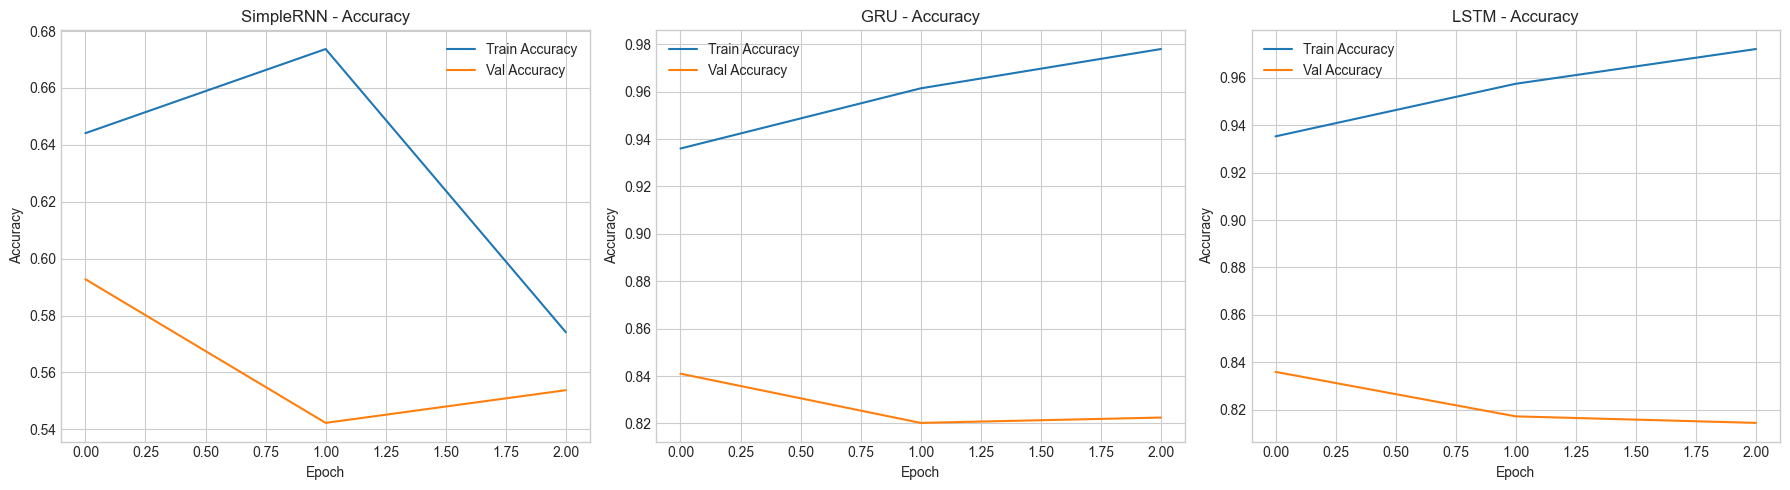

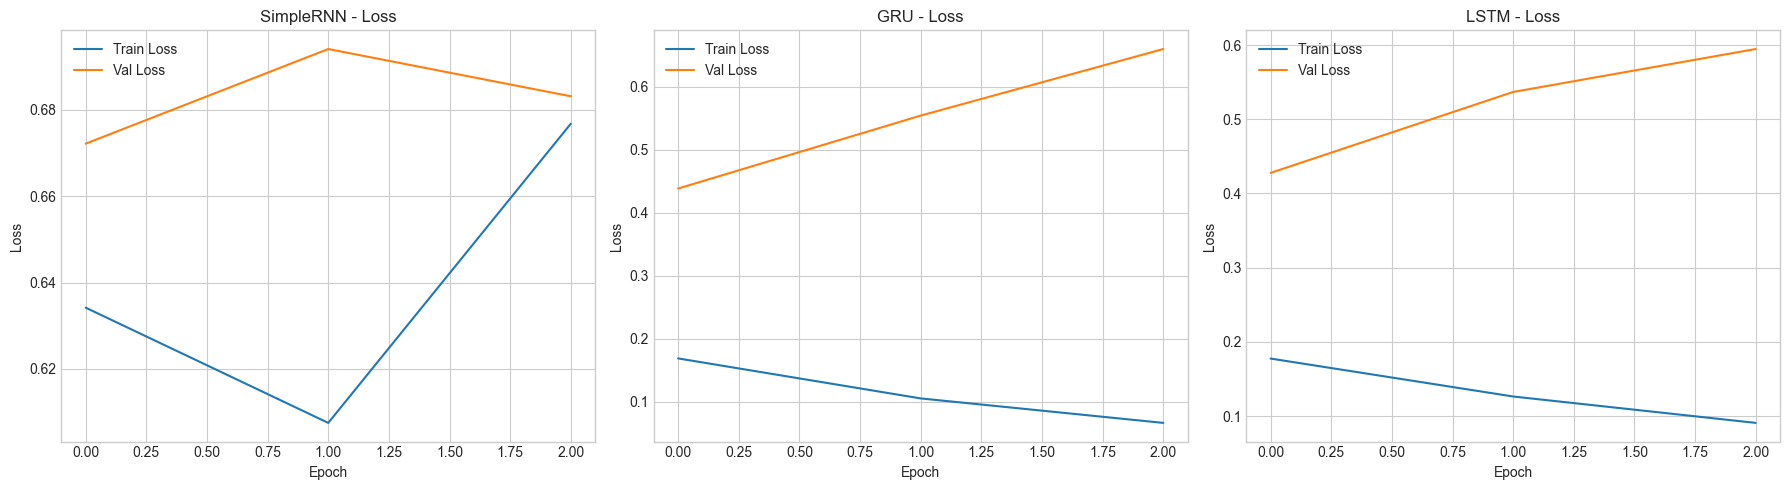

In [ ]:
# 1. Training History Visualization

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, history) in enumerate(history_dict.items()):
    axes[idx].plot(history.history["accuracy"], label=f"Train Accuracy")
    axes[idx].plot(history.history["val_accuracy"], label=f"Val Accuracy")
    axes[idx].set_title(f"{name} - Accuracy")
    axes[idx].set_xlabel("Epoch")
    axes[idx].set_ylabel("Accuracy")
    axes[idx].legend()
    axes[idx].grid(True)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, history) in enumerate(history_dict.items()):
    axes[idx].plot(history.history["loss"], label=f"Train Loss")
    axes[idx].plot(history.history["val_loss"], label=f"Val Loss")
    axes[idx].set_title(f"{name} - Loss")
    axes[idx].set_xlabel("Epoch")
    axes[idx].set_ylabel("Loss")
    axes[idx].legend()
    axes[idx].grid(True)

plt.tight_layout()
plt.show()


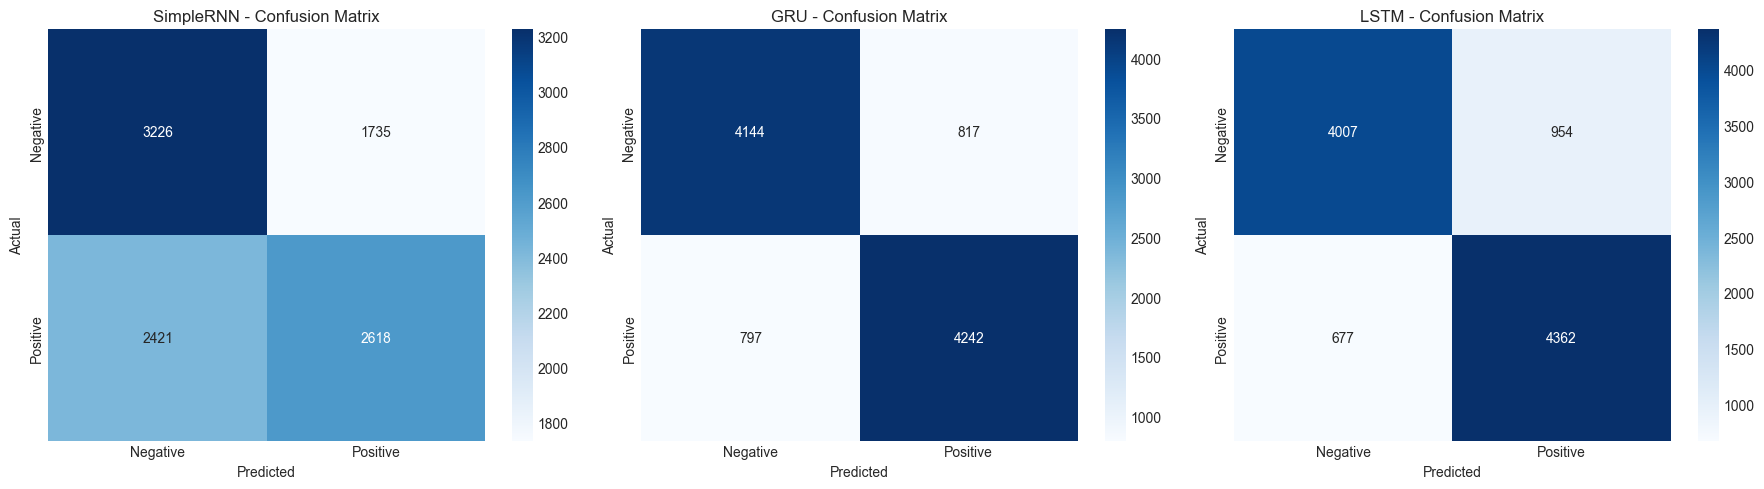

In [ ]:
# 2. Confusion Matrix Visualization

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, result) in enumerate(results.items()):
    y_pred = result["y_pred"].ravel()
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=axes[idx],
    )
    axes[idx].set_title(f"{name} - Confusion Matrix")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.show()


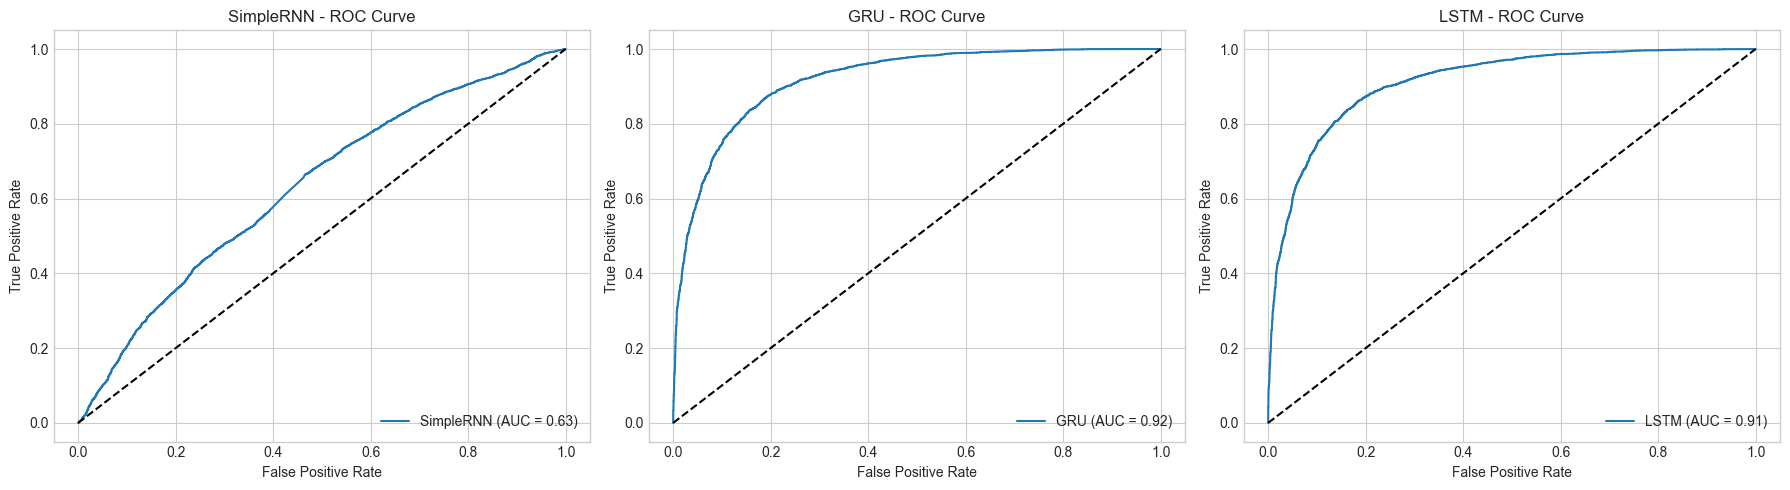


AUC Scores:
+-----------+-------------+
| Model     |   AUC Score |
+===========+=============+
| SimpleRNN |        0.63 |
+-----------+-------------+
| GRU       |        0.92 |
+-----------+-------------+
| LSTM      |        0.91 |
+-----------+-------------+

Classification Reports:

SimpleRNN:
              precision    recall  f1-score   support

           0       0.57      0.65      0.61      4961
           1       0.60      0.52      0.56      5039

    accuracy                           0.58     10000
   macro avg       0.59      0.58      0.58     10000
weighted avg       0.59      0.58      0.58     10000


GRU:
              precision    recall  f1-score   support

           0       0.84      0.84      0.84      4961
           1       0.84      0.84      0.84      5039

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000


LSTM:
              precision    reca

In [ ]:
# 3. ROC Curve and AUC Score

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

roc_metrics = []

for idx, (name, result) in enumerate(results.items()):
    fpr, tpr, _ = roc_curve(y_test, result["y_pred_prob"])
    roc_auc = auc(fpr, tpr)
    roc_metrics.append((name, roc_auc))

    axes[idx].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")
    axes[idx].plot([0, 1], [0, 1], "k--")
    axes[idx].set_xlabel("False Positive Rate")
    axes[idx].set_ylabel("True Positive Rate")
    axes[idx].set_title(f"{name} - ROC Curve")
    axes[idx].legend(loc="lower right")
    axes[idx].grid(True)

plt.tight_layout()
plt.show()

# Print AUC scores table
print("\nAUC Scores:")
table_data = [["Model", "AUC Score"]] + [
    [name, f"{auc_score:.2f}"] for name, auc_score in roc_metrics
]
print(tabulate(table_data, headers="firstrow", tablefmt="grid"))

# Print classification reports
print("\nClassification Reports:")
for name, result in results.items():
    print(f"\n{name}:")
    y_pred = result["y_pred"].ravel()
    print(classification_report(y_test, y_pred))


# 📊 Model Performans Görselleştirmeleri

Bu notebook'a aşağıdaki görselleştirmeler eklendi:

## 1. **Training History Graphs**

- Accuracy curves (train vs validation)
- Loss curves (train vs validation)
- Her model için ayrı grafikler

## 2. **Confusion Matrix**

- True/False Positive ve Negative gösterimi
- Heatmap ile görselleştirme
- Her model için ayrı matrisler

## 3. **ROC Curve & AUC Score**

- Receiver Operating Characteristic curves
- AUC (Area Under Curve) skorları
- Random classifier referans çizgisi

## 4. **Classification Reports**

- Precision, Recall, F1-Score
- Support değerleri
- Her model için detaylı metrikler

### 🎯 Eklenen İyileştirmeler:

- `matplotlib` ve `seaborn` kütüphaneleri
- `sklearn.metrics` fonksiyonları (confusion_matrix, roc_curve, auc)
- `EarlyStopping` ve `ModelCheckpoint` callbacks
- Bidirectional yapılar yerine daha derin network mimarileri
- Validation split ile overfitting kontrolü


In [ ]:
# Preparing Data

y = (data["sentiment"] == "positive").astype(int).values

table = []

In [ ]:
tokenizer = Tokenizer(num_words=10000)
tokenizer.fit_on_texts(data["review"])

word_index = tokenizer.texts_to_sequences(data["review"])

X = pad_sequences(word_index, maxlen=200)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
# Model Training
# For Simple RNN

model_RNN = Sequential(
    [
        Embedding(input_dim=10000, output_dim=32),
        SimpleRNN(32),
        Dense(1, activation="sigmoid"),
    ]
)

model_RNN.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

model_RNN.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.2)

model_RNN.save("model_RNN.keras")

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7351 - loss: 0.5177 - val_accuracy: 0.8346 - val_loss: 0.3797
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8658 - loss: 0.3271 - val_accuracy: 0.8515 - val_loss: 0.3595
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9065 - loss: 0.2416 - val_accuracy: 0.8376 - val_loss: 0.4221
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9433 - loss: 0.1579 - val_accuracy: 0.8220 - val_loss: 0.4979
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9683 - loss: 0.0942 - val_accuracy: 0.7878 - val_loss: 0.5860


In [ ]:
loss_RNN, accuracy_RNN = model_RNN.evaluate(X_test, y_test)

table.append(["Simple RNN", round(accuracy_RNN, 2), round(loss_RNN, 2)])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7955 - loss: 0.5703


In [ ]:
print(f"""
Accuracy Value of Simple RNN: {round(accuracy_RNN, 2)}
Loss Value of Simple RNN: {round(loss_RNN, 2)}
""")


Accuracy Value of Simple RNN: 0.8
Loss Value of Simple RNN: 0.57



In [ ]:
# Model Training
# For Simple GRU

model_GRU = Sequential(
    [
        Embedding(input_dim=10000, output_dim=32),
        GRU(32),
        Dense(1, activation="sigmoid"),
    ]
)

model_GRU.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

model_GRU.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.2)

model_GRU.save("model_GRU.keras")

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.7992 - loss: 0.4197 - val_accuracy: 0.8526 - val_loss: 0.3324
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9006 - loss: 0.2537 - val_accuracy: 0.8773 - val_loss: 0.2908
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9269 - loss: 0.1952 - val_accuracy: 0.8855 - val_loss: 0.2853
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9469 - loss: 0.1495 - val_accuracy: 0.8631 - val_loss: 0.3271
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9608 - loss: 0.1143 - val_accuracy: 0.8790 - val_loss: 0.3361


In [ ]:
loss_GRU, accuracy_GRU = model_GRU.evaluate(X_test, y_test)

table.append(["GRU", round(accuracy_GRU, 2), round(loss_GRU, 2)])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8793 - loss: 0.3280


In [ ]:
print(f"""
Accuracy Value of GRU: {round(accuracy_GRU, 2)}
Loss Value of GRU: {round(loss_GRU, 2)}
""")


Accuracy Value of GRU: 0.88
Loss Value of GRU: 0.33



In [ ]:
# Model Training
# For LSTM

model_LSTM = Sequential(
    [
        Embedding(input_dim=10000, output_dim=32),
        LSTM(32),
        Dense(1, activation="sigmoid"),
    ]
)

model_LSTM.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

model_LSTM.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.2)

model_LSTM.save("model_LSTM.keras")

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.8133 - loss: 0.4006 - val_accuracy: 0.8849 - val_loss: 0.2849
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9066 - loss: 0.2412 - val_accuracy: 0.8846 - val_loss: 0.2789
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9257 - loss: 0.1978 - val_accuracy: 0.8799 - val_loss: 0.3173
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9430 - loss: 0.1584 - val_accuracy: 0.8751 - val_loss: 0.3537
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9552 - loss: 0.1257 - val_accuracy: 0.8739 - val_loss: 0.3395


In [ ]:
loss_LSTM, accuracy_LSTM = model_LSTM.evaluate(X_test, y_test)

table.append(["LSTM", round(accuracy_LSTM, 2), round(loss_LSTM, 2)])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8760 - loss: 0.3212


In [ ]:
print(f"""
Accuracy Value of LSTM: {round(accuracy_LSTM, 2)}
Loss Value of LSTM: {round(loss_LSTM, 2)}
""")


Accuracy Value of LSTM: 0.88
Loss Value of LSTM: 0.32



In [ ]:
# Printing the results

print(
    "Compare the results of the models:\n",
    tabulate(
        table,
        headers=[" Model", "Accuracy ", "Loss "],
        tablefmt="simple",
        numalign="center",
    ),
)

Compare the results of the models:
  Model       Accuracy     Loss
----------  -----------  -------
Simple RNN      0.8       0.57
GRU            0.88       0.33
LSTM           0.88       0.32
